##Import & Dataset Load

In [ ]:
#Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_style("whitegrid")

In [ ]:
# read dataset from a Google Drive File
#file_link = 'https://drive.google.com/file/d/1L2lzFKv6RUTslGImrpI3GI-305KIE3KP/view?usp=sharing' # the file access must have to be Public
#id = file_link.split("/")[-2]
#new_link = f'https://drive.google.com/uc?id={id}'
#print(new_link)
#df = pd.read_csv(new_link)

In [ ]:
#Dataset Uplaod

#from google.colab import files
#uploaded = files.upload()

In [ ]:
loc="/content/Conflict data set (2019-2026).csv"

In [ ]:
df = pd.read_csv("Conflict data set (2019-2026).csv")

df.head()

,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1,...,latitude,longitude,geo_precision,source,source_scale,notes,fatalities,tags,ts,population_5km
0,CHN1842,20190101.0,2019.0,2.0,0.0,Strategic developments,0.0,Police Forces of China (2012-),NaN,0.0,...,28.6739,121.4424,2.0,Bitter Winter,Other,"Around 1 January 2019 (beginning of month), a ...",0.0,NaN,1.618527e+09,349298.0
1,CHN1696,20190101.0,2019.0,1.0,1.0,Protests,1.0,Protesters (China),NaN,1.0,...,22.2811,114.1598,1.0,Apple Daily Hong Kong,Subnational,"On 1 January 2019, during the New Year's Day R...",0.0,crowd size=dozens,1.611095e+09,235951.0
2,TWN5,20190101.0,2019.0,1.0,1.0,Riots,2.0,Rioters (Taiwan),Tax and Legal Reform League,2.0,...,25.0326,121.5181,1.0,China Times,National,"On 1 January 2019, 20-30 members of the Tax an...",0.0,crowd size=20-30,1.618581e+09,238221.0
3,KOR7,20190101.0,2019.0,1.0,1.0,Protests,1.0,Protesters (South Korea),NaN,1.0,...,37.5945,126.9711,1.0,NEWSIS,National,"On 1 January 2019, parents of Unpaid Child Sup...",0.0,crowd size=no report,1.611098e+09,45717.0
4,MMR6313,20190101.0,2019.0,1.0,2.0,Battles,3.0,Police Forces of Myanmar (2016-2021) Border Gu...,Military Forces of Myanmar (2016-2021),0.0,...,20.7264,92.6711,1.0,Irrawaddy,National,"On 1 January 2019, in Say Taung Village, in Bu...",0.0,NaN,1.612999e+09,1862.0


##EDA

In [ ]:
# Show all column names
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['event_id_cnty', 'event_date', 'year', 'time_precision',
       'disorder_type', 'event_type', 'sub_event_type', 'actor1',
       'assoc_actor_1', 'inter1', 'actor2', 'assoc_actor_2', 'inter2',
       'interaction', 'civilian_targeting', 'iso', 'region', 'country',
       'admin1', 'admin2', 'admin3', 'location', 'latitude', 'longitude',
       'geo_precision', 'source', 'source_scale', 'notes', 'fatalities',
       'tags', 'ts', 'population_5km'],
      dtype='object')


In [ ]:
#Dataset Load

#df=pd.read_csv(loc)
#df.head()

In [ ]:
#Dataset Basic Info

print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (364444, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364444 entries, 0 to 364443
Data columns (total 32 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   event_id_cnty       364444 non-null  object 
 1   event_date          364438 non-null  float64
 2   year                364438 non-null  float64
 3   time_precision      364438 non-null  float64
 4   disorder_type       364438 non-null  float64
 5   event_type          364438 non-null  object 
 6   sub_event_type      364438 non-null  float64
 7   actor1              364438 non-null  object 
 8   assoc_actor_1       239187 non-null  object 
 9   inter1              364438 non-null  float64
 10  actor2              99749 non-null   object 
 11  assoc_actor_2       29139 non-null   object 
 12  inter2              99749 non-null   object 
 13  interaction         364438 non-null  float64
 14  civilian_targeting  12401 non-null   object 
 15  iso   

In [ ]:
#Checking Missing Values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values.sort_values(ascending=False)

,0
civilian_targeting,352043
assoc_actor_2,335305
inter2,264695
actor2,264695
assoc_actor_1,125257
admin3,101796
tags,65247
admin2,2845
population_5km,680
admin1,7


In [ ]:
df.describe() #Dataset Statistical Summary

,event_date,year,time_precision,disorder_type,sub_event_type,inter1,interaction,iso,region,latitude,longitude,geo_precision,fatalities,ts,population_5km
count,3.644380e+05,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.000000,364438.00000,3.644380e+05,3.637640e+05
mean,2.021739e+07,2021.672416,1.060825,1.156273,1.760651,1.183057,2.227899,331.309276,2.019954,24.938105,90.893416,1.229090,0.41752,1.711035e+09,2.365524e+05
std,1.770336e+04,1.773105,0.246370,0.459914,1.529840,0.792960,2.968235,179.829371,1.208471,9.985852,20.555076,0.455111,2.68706,4.541993e+07,2.896933e+05
min,2.019010e+07,2019.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000,-10.724800,61.104400,1.000000,0.00000,1.557839e+09,0.000000e+00
25%,2.020092e+07,2020.000000,1.000000,1.000000,1.000000,1.000000,1.000000,156.000000,1.000000,21.556525,74.872800,1.000000,0.00000,1.680634e+09,3.441500e+04
50%,2.022031e+07,2022.000000,1.000000,1.000000,1.000000,1.000000,1.000000,356.000000,3.000000,26.130900,85.371100,1.000000,0.00000,1.721769e+09,1.281540e+05
75%,2.023092e+07,2023.000000,1.000000,1.000000,2.000000,1.000000,1.000000,410.000000,3.000000,32.613600,98.289100,1.000000,0.00000,1.750794e+09,3.324620e+05
max,2.025030e+07,2025.000000,3.000000,3.000000,10.000000,6.000000,21.000000,764.000000,3.000000,50.780300,145.582400,3.000000,400.00000,1.771963e+09,2.581592e+06


In [ ]:
df["fatalities"].describe() #Check Fatalities Column

,fatalities
count,364438.00000
mean,0.41752
std,2.68706
min,0.00000
25%,0.00000
50%,0.00000
75%,0.00000
max,400.00000


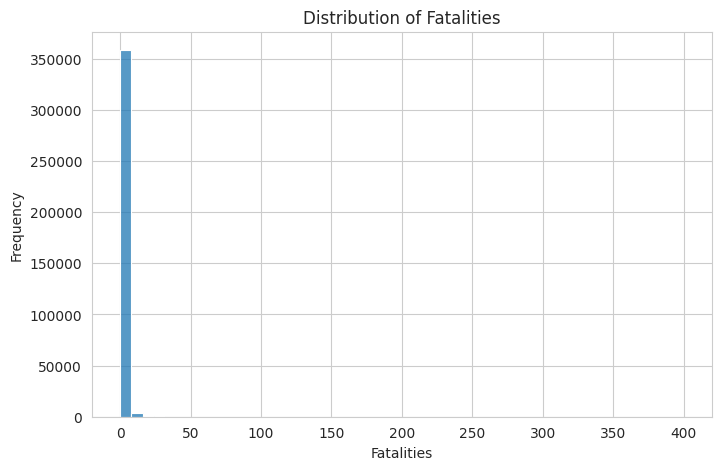

In [ ]:
# Distribution of fatalities
plt.figure(figsize=(8,5))
sns.histplot(df["fatalities"], bins=50)
plt.title("Distribution of Fatalities")
plt.xlabel("Fatalities")
plt.ylabel("Frequency")
plt.show()

0 → No fatality  
1 → Fatality occurred

In [ ]:
#Creating Target Variable (Fatality Prediction)

df["fatal_event"] = df["fatalities"].apply(lambda x: 1 if x > 0 else 0)

df["fatal_event"].value_counts()

,count
fatal_event,
0,335593
1,28851


In [ ]:
# Check class balance
print(df["fatal_event"].value_counts())

# Percentage
print(df["fatal_event"].value_counts(normalize=True))

fatal_event
0    335593
1     28851
Name: count, dtype: int64
fatal_event
0    0.920836
1    0.079164
Name: proportion, dtype: float64


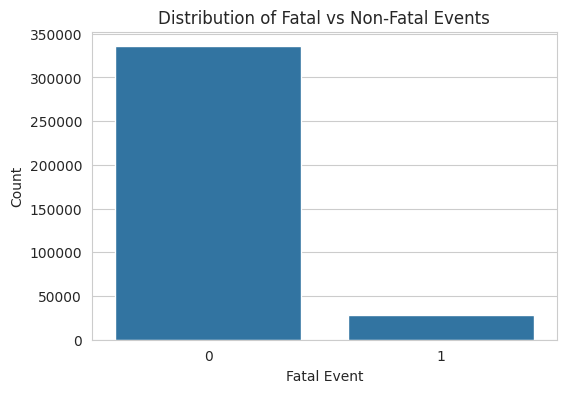

In [ ]:
#Target Distribution

plt.figure(figsize=(6,4))
sns.countplot(x="fatal_event", data=df)

plt.title("Distribution of Fatal vs Non-Fatal Events")
plt.xlabel("Fatal Event")
plt.ylabel("Count")

plt.show()

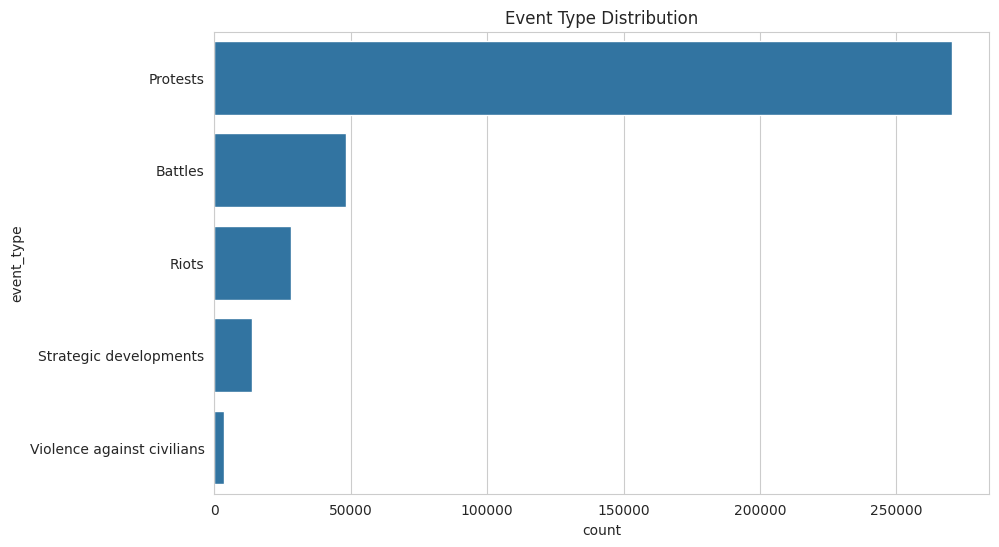

In [ ]:
#Event Type Distribution

plt.figure(figsize=(10,6))

sns.countplot(
    y="event_type",
    data=df,
    order=df["event_type"].value_counts().index
)

plt.title("Event Type Distribution")

plt.show()

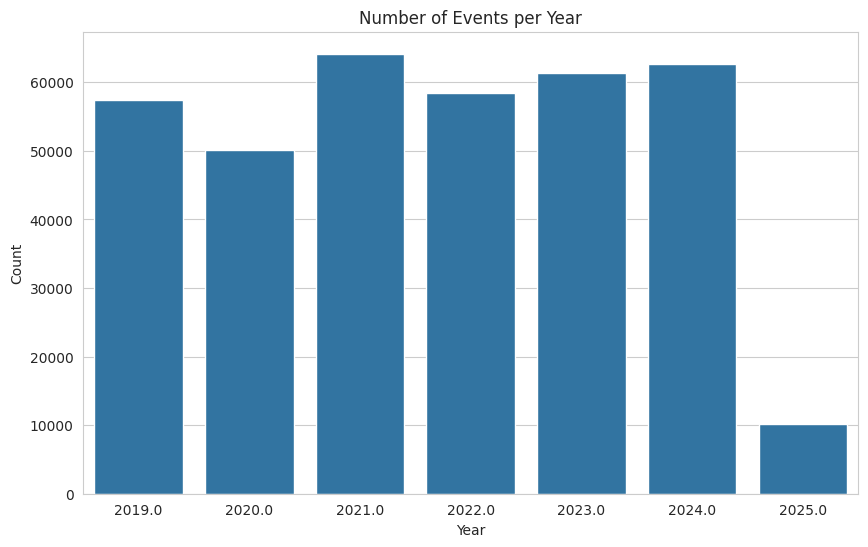

In [ ]:
# Events by year
plt.figure(figsize=(10,6))
sns.countplot(x="year", data=df)
plt.title("Number of Events per Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

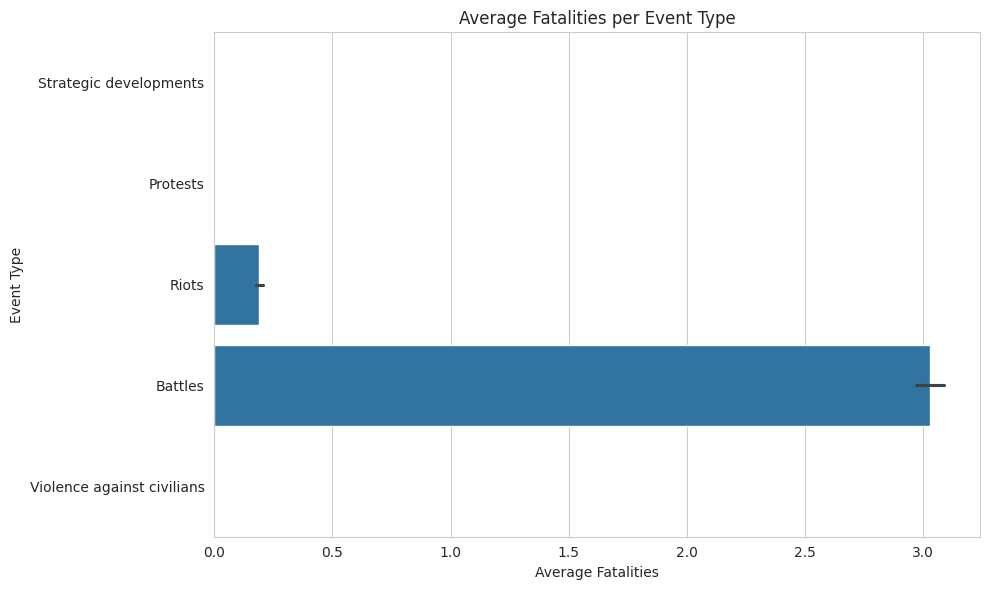

In [ ]:
#Fatalities by Event Type

plt.figure(figsize=(10,6))

sns.barplot(
    x="fatalities",
    y="event_type",
    data=df,
    estimator=np.mean
)

plt.title("Average Fatalities per Event Type")
plt.xlabel("Average Fatalities")
plt.ylabel("Event Type")
plt.tight_layout()
plt.savefig("fatalities_by_event_type.png", dpi=300, bbox_inches="tight")

plt.show()

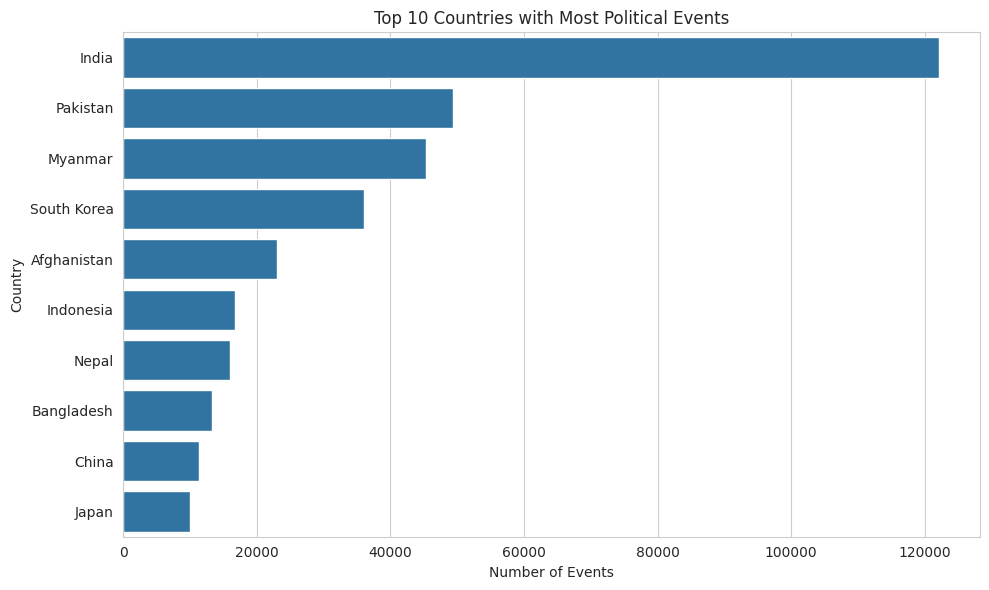

In [ ]:
#Top Countries with Most Events

top_countries = df["country"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries with Most Political Events")
plt.xlabel("Number of Events")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("top_countries.png", dpi=300, bbox_inches="tight")

plt.show()

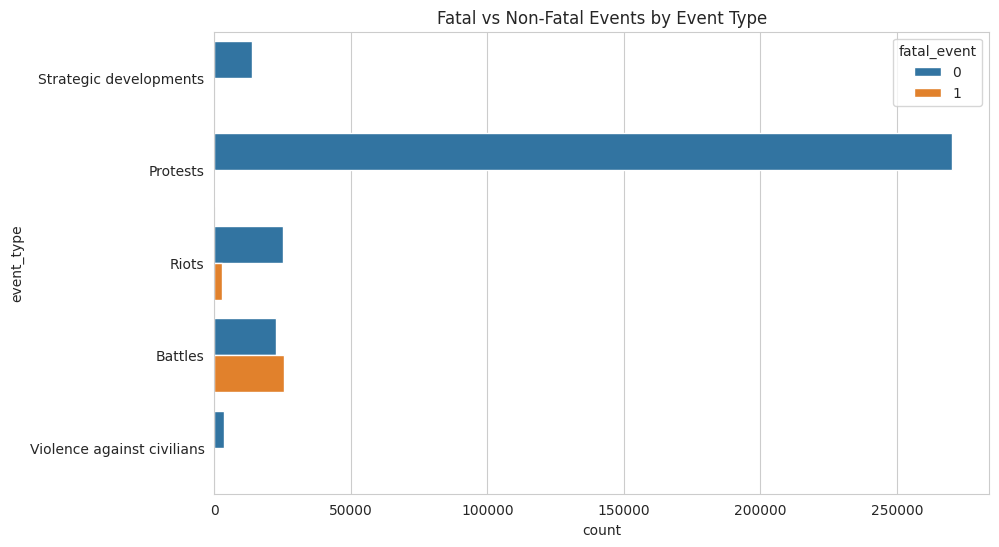

In [ ]:
#Fatal vs Non-Fatal Events by Event Type

plt.figure(figsize=(10,6))

sns.countplot(
    y="event_type",
    hue="fatal_event",
    data=df
)

plt.title("Fatal vs Non-Fatal Events by Event Type")

plt.show()

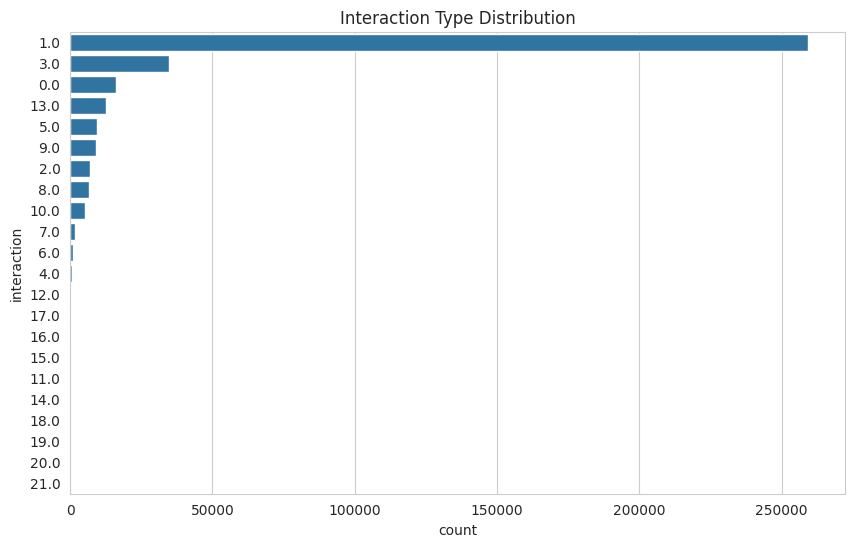

In [ ]:
#Actor Interaction Analysis

plt.figure(figsize=(10,6))

sns.countplot(
    y="interaction",
    data=df,
    order=df["interaction"].value_counts().index
)

plt.title("Interaction Type Distribution")

plt.show()

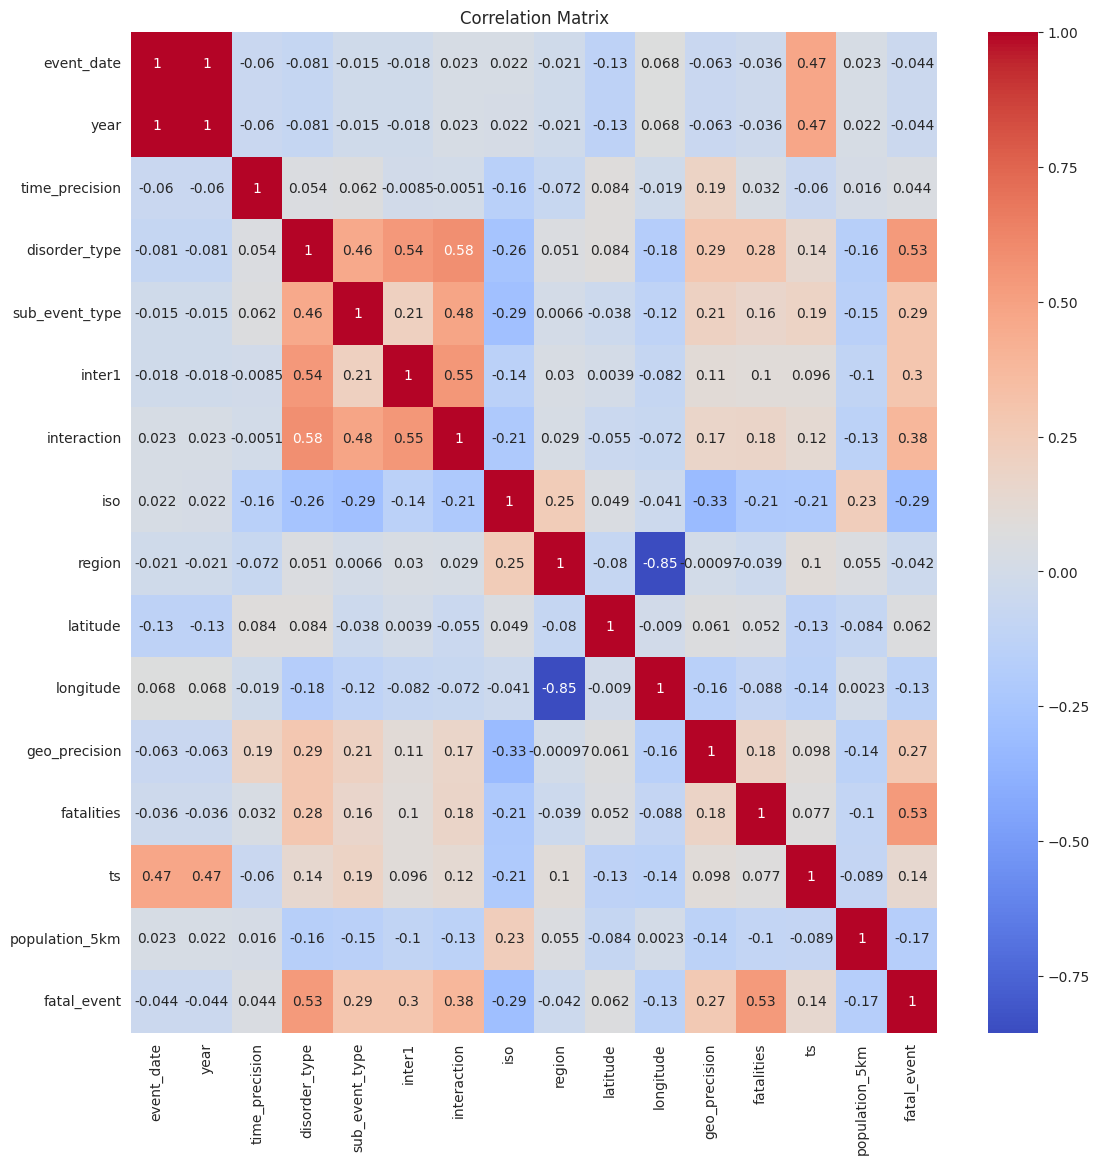

In [ ]:
#Correlation Matrix (Numeric Columns)

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(13,13))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

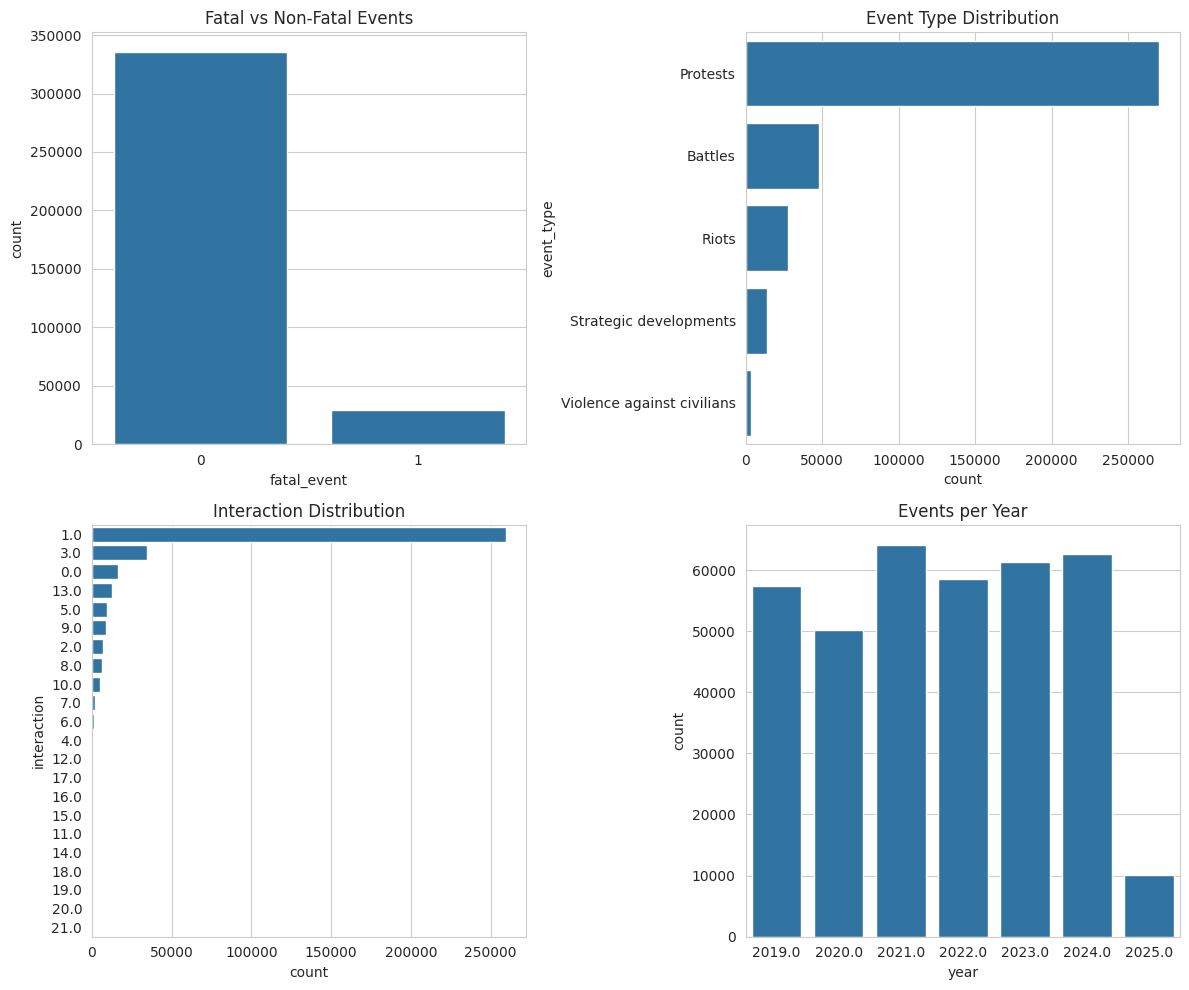

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,10))

# Plot 1: Target distribution
plt.subplot(2,2,1)
sns.countplot(x="fatal_event", data=df)
plt.title("Fatal vs Non-Fatal Events")

# Plot 2: Event Type Distribution
plt.subplot(2,2,2)
sns.countplot(y="event_type", data=df, order=df["event_type"].value_counts().index)
plt.title("Event Type Distribution")

# Plot 3: Interaction Distribution
plt.subplot(2,2,3)
sns.countplot(y="interaction", data=df, order=df["interaction"].value_counts().index)
plt.title("Interaction Distribution")

# Plot 4: Events per Year
plt.subplot(2,2,4)
sns.countplot(x="year", data=df)
plt.title("Events per Year")

plt.tight_layout()
plt.savefig("eda_combined.png", dpi=300, bbox_inches="tight")
plt.show()

##Pre Processing

In [ ]:
# Drop unnecessary columns

drop_cols = ["event_date", "notes", "source", "timestamp"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

In [ ]:
#Select Important Features

features = [
    "event_type",
    "sub_event_type",
    "country",
    "interaction",
    "region",
    "year",
    "population_5km"
]

X = df[features]

y = df["fatal_event"]

In [ ]:
#Convert Categorical Features

X = pd.get_dummies(X)

# Fill missing values
X = X.fillna(0)

X.head()

,sub_event_type,interaction,region,year,population_5km,event_type_Battles,event_type_Protests,event_type_Riots,event_type_Strategic developments,event_type_Violence against civilians,...,country_Nepal,country_North Korea,country_Pakistan,country_Philippines,country_Singapore,country_South Korea,country_Sri Lanka,country_Taiwan,country_Thailand,country_Vietnam
0,0.0,0.0,0.0,2019.0,349298.0,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
1,1.0,1.0,0.0,2019.0,235951.0,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2.0,2.0,0.0,2019.0,238221.0,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,1.0,1.0,0.0,2019.0,45717.0,False,True,False,False,False,...,False,False,False,False,False,True,False,False,False,False
4,3.0,3.0,1.0,2019.0,1862.0,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
#Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (291555, 35)
Testing Data: (72889, 35)


##Model Implementation


In [ ]:
# importing ML Libraries

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from catboost import CatBoostClassifier

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
!pip install catboost

In [ ]:
#Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9377546680569084
              precision    recall  f1-score   support

           0       0.98      0.95      0.97     67183
           1       0.58      0.77      0.66      5706

    accuracy                           0.94     72889
   macro avg       0.78      0.86      0.81     72889
weighted avg       0.95      0.94      0.94     72889



In [ ]:
# Decision Tree

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.940855273086474
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     67183
           1       0.63      0.60      0.61      5706

    accuracy                           0.94     72889
   macro avg       0.80      0.79      0.79     72889
weighted avg       0.94      0.94      0.94     72889



In [ ]:
#Random Forest

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9412531383336306
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     67183
           1       0.62      0.64      0.63      5706

    accuracy                           0.94     72889
   macro avg       0.80      0.80      0.80     72889
weighted avg       0.94      0.94      0.94     72889



In [ ]:
# Gradient Boosting

gb_model = GradientBoostingClassifier(random_state=42)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.9424055756012567
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     67183
           1       0.63      0.65      0.64      5706

    accuracy                           0.94     72889
   macro avg       0.80      0.81      0.80     72889
weighted avg       0.94      0.94      0.94     72889



In [ ]:
#AdaBoost

ab_model = AdaBoostClassifier(n_estimators=100, random_state=42)

ab_model.fit(X_train, y_train)

y_pred_ab = ab_model.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ab))
print(classification_report(y_test, y_pred_ab))

AdaBoost Accuracy: 0.9340778443935299
              precision    recall  f1-score   support

           0       0.97      0.95      0.96     67183
           1       0.56      0.70      0.63      5706

    accuracy                           0.93     72889
   macro avg       0.77      0.83      0.79     72889
weighted avg       0.94      0.93      0.94     72889



In [ ]:
#XGBoost

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9439147196421956
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     67183
           1       0.63      0.68      0.65      5706

    accuracy                           0.94     72889
   macro avg       0.80      0.82      0.81     72889
weighted avg       0.95      0.94      0.94     72889



In [ ]:
#CatBoost

cat_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    random_state=42,
    verbose=0
)

cat_model.fit(X_train, y_train)

y_pred_cat = cat_model.predict(X_test)

print("CatBoost Accuracy:", accuracy_score(y_test, y_pred_cat))
print(classification_report(y_test, y_pred_cat))

CatBoost Accuracy: 0.944038195063727
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     67183
           1       0.63      0.69      0.66      5706

    accuracy                           0.94     72889
   macro avg       0.80      0.83      0.81     72889
weighted avg       0.95      0.94      0.95     72889



##Evaluation

In [ ]:
#from sklearn.metrics import classification_report

report_xgb = classification_report(y_test, y_pred_xgb, output_dict=True)
df_report_xgb = pd.DataFrame(report_xgb).transpose()

print(df_report_xgb)

              precision    recall  f1-score       support
0              0.972487  0.966495  0.969482  67183.000000
1              0.632190  0.678058  0.654321   5706.000000
accuracy       0.943915  0.943915  0.943915      0.943915
macro avg      0.802338  0.822276  0.811901  72889.000000
weighted avg   0.945848  0.943915  0.944810  72889.000000


In [ ]:
results = {
    "Logistic Regression": accuracy_score(y_test, y_pred_lr),
    "Decision Tree": accuracy_score(y_test, y_pred_dt),
    "Random Forest": accuracy_score(y_test, y_pred_rf),
    "Gradient Boosting": accuracy_score(y_test, y_pred_gb),
    "AdaBoost": accuracy_score(y_test, y_pred_ab),
    "XGBoost": accuracy_score(y_test, y_pred_xgb),
    "CatBoost": accuracy_score(y_test, y_pred_cat)
}

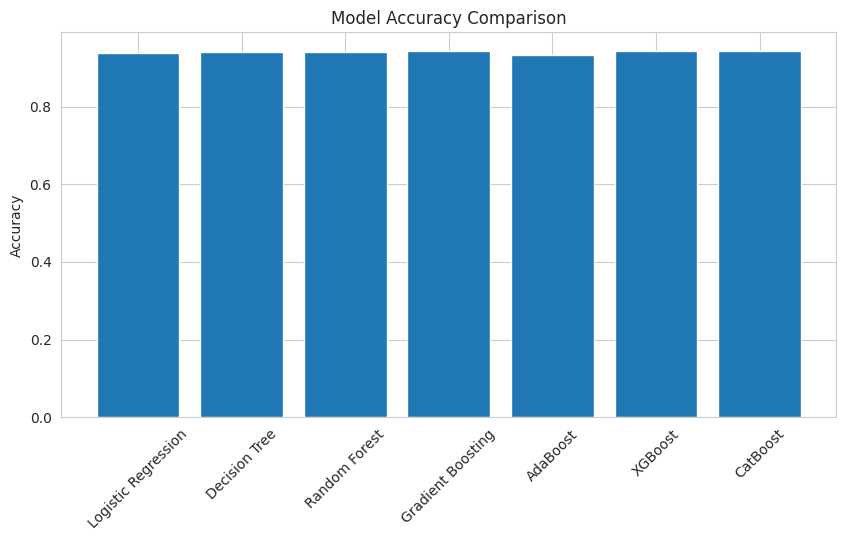

In [ ]:
#Accuracy Bar Plot

plt.figure(figsize=(10,5))
plt.bar(results.keys(), results.values())

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)

plt.show()

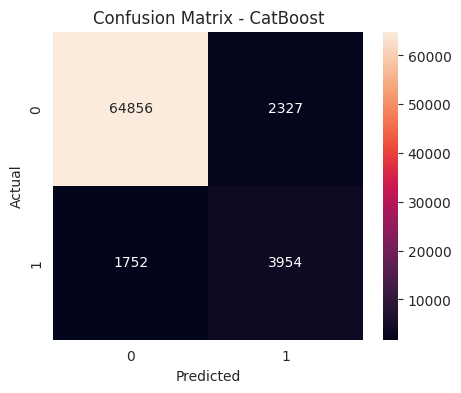

In [ ]:
#Confusion Matrix

cm = confusion_matrix(y_test, y_pred_cat)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d')

plt.title("Confusion Matrix - CatBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("confusion_matrix_catboost.png", dpi=300, bbox_inches="tight")
plt.show()

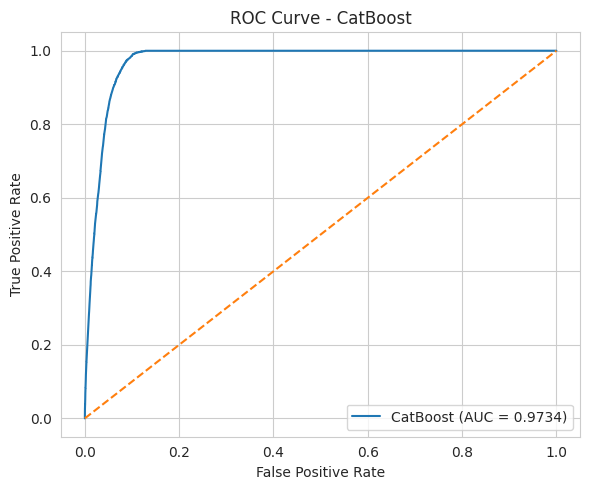

In [ ]:
#ROC-AUC

y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]
y_prob_ab = ab_model.predict_proba(X_test)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_prob_cat = cat_model.predict_proba(X_test)[:, 1]

roc_lr = roc_auc_score(y_test, y_prob_lr)
roc_dt = roc_auc_score(y_test, y_prob_dt)
roc_rf = roc_auc_score(y_test, y_prob_rf)
roc_gb = roc_auc_score(y_test, y_prob_gb)
roc_ab = roc_auc_score(y_test, y_prob_ab)
roc_xgb = roc_auc_score(y_test, y_prob_xgb)
roc_cat = roc_auc_score(y_test, y_prob_cat)

fpr, tpr, _ = roc_curve(y_test, y_prob_cat)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"CatBoost (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - CatBoost")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_catboost.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
all_model_metrics = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "AdaBoost",
        "XGBoost",
        "CatBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_ab),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_cat)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb),
        precision_score(y_test, y_pred_ab),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_cat)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb),
        recall_score(y_test, y_pred_ab),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_cat)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb),
        f1_score(y_test, y_pred_ab),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_cat)
    ],
    "ROC-AUC": [
        roc_lr,
        roc_dt,
        roc_rf,
        roc_gb,
        roc_ab,
        roc_xgb,
        roc_cat
    ]
})

print(all_model_metrics.round(4))

                 Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0  Logistic Regression    0.9378     0.5772  0.7659    0.6583   0.9637
1        Decision Tree    0.9409     0.6272  0.6029    0.6148   0.8743
2        Random Forest    0.9413     0.6216  0.6379    0.6296   0.9574
3    Gradient Boosting    0.9424     0.6270  0.6523    0.6394   0.9717
4             AdaBoost    0.9341     0.5631  0.7042    0.6258   0.9622
5              XGBoost    0.9439     0.6322  0.6781    0.6543   0.9732
6             CatBoost    0.9440     0.6295  0.6930    0.6597   0.9734
